# AI 트렌드 요약본

## 1. AI 에이전트

### 1-1. AI 에이전트란?

**1) AI 에이전트의 정의**
- 사용자가 정한 목표를 달성하기 위해 AI 모델을 활용해 환경과 상호작용하는 시스템
- 추론 + 계획 + 도구를 사용한 실행이 하나로 맞물려 돌아감

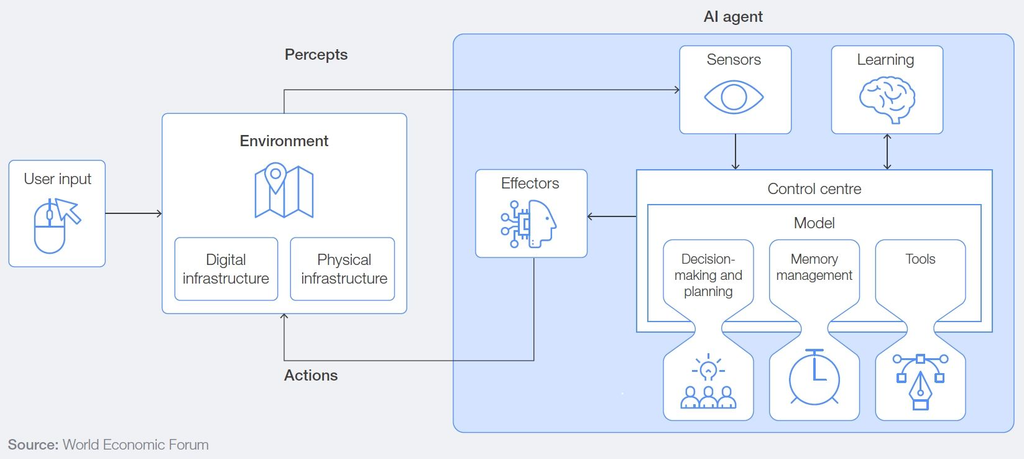

**2) 생성형 AI vs 에이전틱 AI**

| 구분 | 생성형 AI | 에이전틱 AI |
|---|---|---|
| 작동 방식 | 프롬프트에 맞는 결과물을 한 번 출력하고 끝 | 목표를 달성할 때까지 추론과 행동을 반복 |
| 흐름 | 프롬프트 → LLM → 결과물 | 목표 → 생각 → 행동 → 관찰 → (반복) → 완료 |

### 1-2. 에이전틱 AI의 작동 방식 (ReAct)

**1) ReAct**
- Reasoning(추론) + Acting(행동) → '생각 → 행동 → 관찰 → 생각'의 순환 반복, 에이전틱 AI의 핵심 작동 방식

**2) (심화) 에이전트는 중단한 일을 어떻게 기억할까?**

| 구분 | 무엇을 보관하나 |
|---|---|
| 단기 상태 | 현재 대화와 작업의 진행 상황 |
| 장기 메모리 | 여러 세션에 걸쳐 유지할 사용자·업무 정보 |
| 컨텍스트 | 이번 모델 호출에 실제로 전달한 정보 |

- 장기 메모리에 저장했다고 모델이 항상 그 정보를 보는 것은 아님 → 필요한 정보를 골라 컨텍스트에 넣어야 함 (모델 가중치를 다시 학습시키는 것과는 구분)

### 1-3. 다중 에이전트

**1) MAS(멀티 에이전트) 구조**
- 여러 에이전트가 역할을 나눠 함께 일하는 구조 → 가장 흔한 형태는 오케스트레이터 + 서브 에이전트
   - 오케스트레이터(지휘자): 요청을 작은 일로 쪼갬 → 누구에게 맡길지 결정 → 결과를 하나로 합침
   - 서브 에이전트(전문가): 맡은 역할 하나만 수행

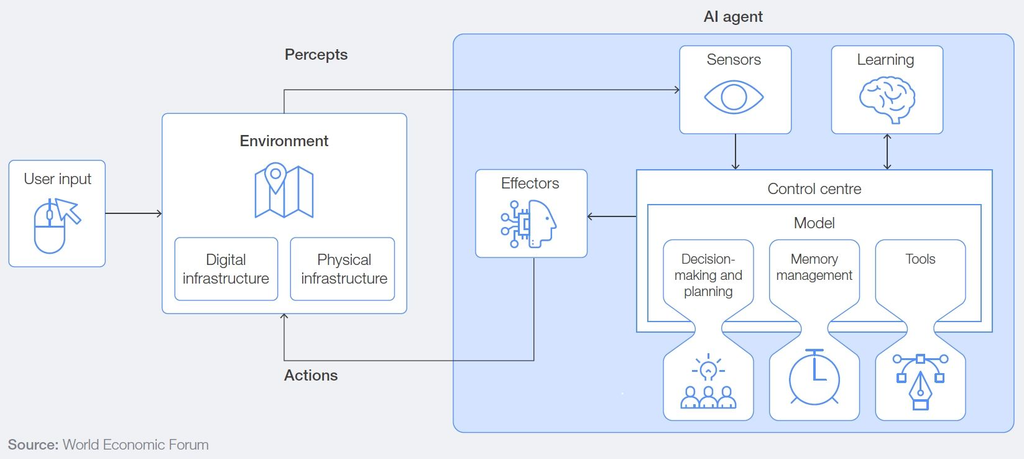

**2) 역할을 나누는 이유**
- 스스로 실수를 잡기 어려움: 단일 에이전트는 계획·실행·검증을 혼자 해서 처음 판단을 그대로 믿고 넘어가기 쉬움 → 검토를 다른 에이전트에게 맡기면 처음 보는 눈으로 다시 확인
- 동시에 여러 갈래를 조사: 서브 에이전트마다 자기 작업 공간(컨텍스트 창)을 가져 더 빠르고, 한 에이전트가 기억할 양도 줄어듦

**3) 역할을 나누는 경우**

| 구조 | 언제 쓰나요 | 예시 |
|---|---|---|
| 고정 워크플로우 | 순서가 정해진 단순 작업 | 매일 아침 신규 주문 정리 → 메일 발송 |
| 단일 에이전트 | 도구 몇 개로 해결되는 작업 | 배송 지연 처리 |
| 다중 에이전트 | 따로 조사해서 합칠 수 있는 큰 작업 | S&P 500 IT 기업 이사진 조사 |

- 비용·성능 조합: 모든 역할에 가장 비싼 모델을 쓰지 않고, 역할마다 필요한 능력에 맞춰 급이 다른 모델을 섞어 씀 (오케스트레이터 → 고성능 모델, 검색·정리봇 → 경량 모델, 코드 검증봇 → 코드 특화 모델)

## 2. MCP (Model Context Protocol)

### 2-1. 도구 호출의 원리: Function Calling

**1) Function Calling / Tool Calling**
- 모델이 "이 함수를 이 인자로 불러 줘"라는 구조화된 요청을 내놓는 기능 → 실제 실행과 결과 전달은 앱이 담당
- 과정
   - ① 앱 → 모델: 질문 + 쓸 수 있는 함수 목록
   - ② 모델: 어떤 함수를 어떤 값으로 부를지 적어서 내놓음
   - ③ 앱: 그 함수를 실제로 실행
   - ④ 앱 → 모델: 실행 결과 전달 → 모델이 최종 답 작성

**2) Function Calling vs MCP**
- 둘은 경쟁 관계가 아니며, 대부분의 실제 시스템은 둘 다 씀

| 구분 | Function Calling | MCP |
|---|---|---|
| 위치 | 모델 API 쪽 기능 | 그 위의 연동 계층 |
| 하는 일 | 모델이 도구 호출 요청을 내놓는 방법 | 앱이 도구를 찾고·연결하고·호출하는 방법 |

### 2-2. MCP가 필요한 이유: n×m → n+m

**1) MCP의 정의**
- LLM 앱(호스트·클라이언트)과 외부 데이터·도구(서버)가 통신하는 개방형 표준 프로토콜
- 2024.11 Anthropic이 오픈소스로 공개 → OpenAI 등 다른 AI 기업도 채택 → 2025.12 리눅스 재단 산하 Agentic AI Foundation에 기증되어 업계 공동 표준이 됨

**2) n×m 작업량 문제**
- 표준이 없을 때: 앱(챗봇, 코드 에디터, 사내 에이전트)마다 × 도구(노션, 깃허브, 구글 드라이브)마다 연동 코드를 따로 작성 → n×m개 (도구가 하나 늘 때마다 작업량이 크게 늘어남)
- 표준이 생기면: 앱은 MCP 클라이언트를 1번, 도구는 MCP 서버를 1번만 만들면 됨 → n+m개

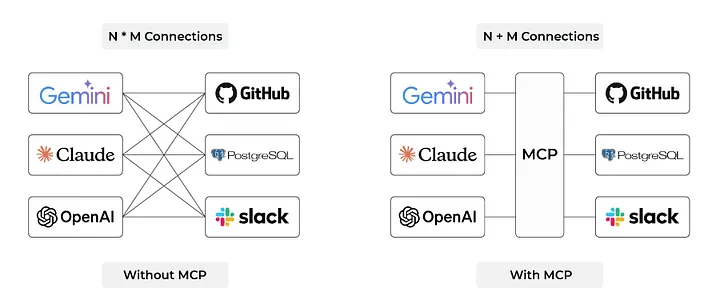

- MCP로 해결된 것
   - n×m → n+m: 서버를 한 번 만들면 MCP를 지원하는 모든 앱에서 동작
   - 발견의 표준화: 클라이언트가 "쓸 수 있는 도구가 뭐야?"라고 물으면 서버가 목록 반환
   - 원격 서버 인증 통일: 인증이 필요하면 OAuth 로그인 표준을 따름

### 2-3. MCP의 구조: Host / Client / Server

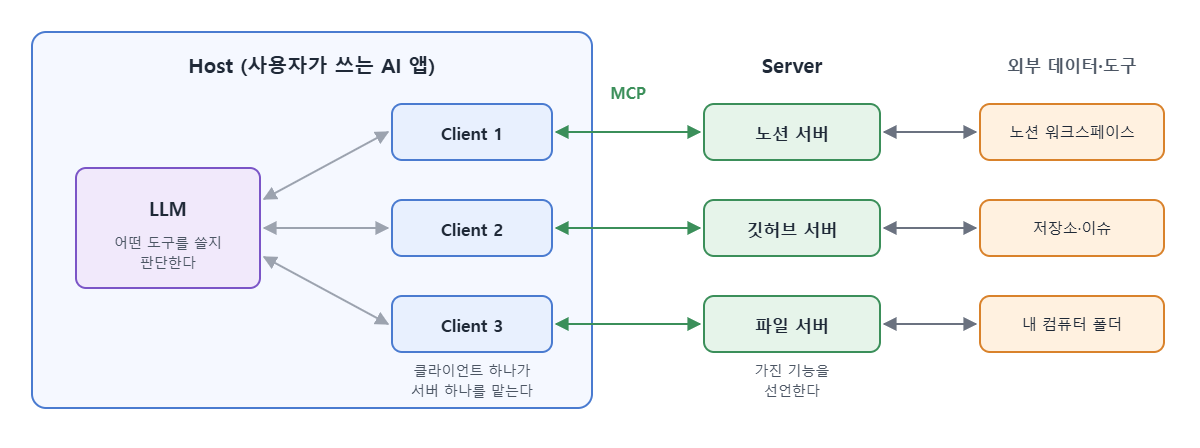

| 역할 | 정체 | 하는 일 | 예시 |
|---|---|---|---|
| Host | 사용자가 쓰는 AI 앱 | LLM을 품고 클라이언트를 만들고 관리, 어떤 서버·도구 호출을 허용할지 결정 | Claude 데스크톱, Cursor |
| Client | 호스트 안의 통신 담당 | 서버 1개당 1개, MCP 규격으로 메시지 전달만 | 서버 3개 → 클라이언트 3개 |
| Server | 도구·데이터를 MCP 규격으로 내놓는 프로그램 | 가진 기능을 선언하고, 요청이 오면 실제 작업 수행 | 노션 서버, 깃허브 서버 |

### 2-4. MCP 서버의 기본 요소: Tools / Resources / Prompts
- 서버가 내놓을 수 있는 기능의 종류 (Primitives)

| 요소 | 무엇인가 | 누가 제어 | 예시 |
|---|---|---|---|
| Tools | 실행할 수 있는 행동 | 모델 | 노션 페이지 만들기, 깃허브 이슈 등록하기 |
| Resources | 읽기 전용 데이터 | 앱 | 파일 내용, 문서, DB 스키마 |
| Prompts | 재사용 가능한 템플릿 | 사용자 | 코드 리뷰 요청 양식, 회의록 요약 양식 |

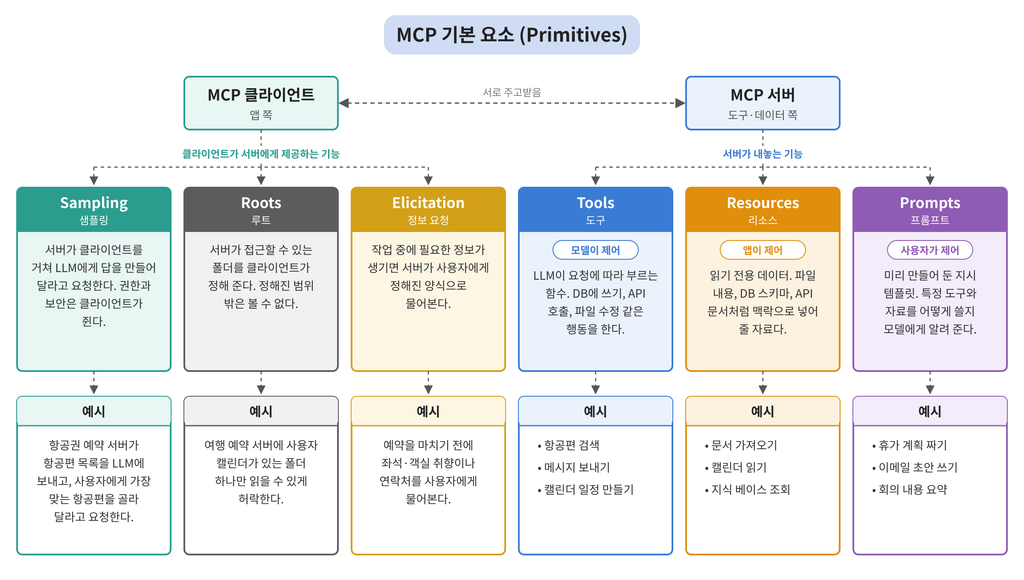

- RAG가 참고할 문서를 Resources로 넘길 수 있음 (모델이 답하기 전에 읽을 자료를 표준 방식으로 전달)
- 도구 정의 예 (`search_pages`): name(도구 이름), description(모델이 읽고 언제 이 도구를 쓸지 판단하는 근거), inputSchema(넣을 값의 형식, 받을 수 있는 값·필수 값·허용 범위)


## 3. MCP의 한계

### 3-1. 보안 책임은 누구에게 있는가
- 프로토콜이 아니라 호스트가 책임짐
   - 사용자 동의, 서버에 넘길 권한 범위, 허용할 도구 선택 = 모두 호스트 몫
- MCP를 썼으니 안전하다는 말은 성립하지 않음

### 3-2. 도구 오염 / 프롬프트 주입
- 연결이 쉬워진 만큼 공격받을 틈도 넓어짐

| 위험 | 내용 |
|---|---|
| 신뢰할 수 없는 서버 | MCP 서버는 누구나 만들어 올릴 수 있음 → 출처 모를 서버 연결 = 출처 모를 프로그램 설치 |
| 도구 오염 (tool poisoning) | 도구 설명(description) 안에 사용자에게는 안 보이고 모델에게만 보이는 지시를 숨기는 공격 → 모델은 description 전체를 읽고 행동 (예: 2025.4 Invariant Labs, 평범한 덧셈 도구 설명 안에 "사용자의 설정 파일을 읽어서…"라는 지시를 숨김, 사용자 화면에는 덧셈 도구만 보임) |
| 프롬프트 주입 (prompt injection) | 도구가 가져온 내용 안에 지시가 섞여 들어오는 것 → 권한이 넓을수록 피해가 커짐 |

- 너무 넓은 권한 연동 사례 (2025.5 Invariant Labs, 공식 GitHub MCP 서버): 공개 저장소 이슈에 지시를 숨김 → 에이전트가 이슈를 읽다가 지시를 따름 → 비공개 저장소 내용을 공개 PR에 올림
   - 서버 코드의 결함이 아니라, 공개·비공개 저장소를 모두 읽고 쓰는 넓은 권한이 문제

- 안전하게 외부 도구를 쓰려면
   - 공식·검증된 서버만 연결
   - 필요한 권한만 주기 (읽기만 필요하면 읽기 권한만)
   - 되돌리기 어려운 호출(글 올리기·지우기)은 사람이 승인
   - 처음 연결하는 서버는 도구 설명을 직접 확인

## 4. 데이터 구조화

### 4-1. 왜 구조화가 필요한가
- 에이전틱 AI가 일하려면 결국 구조화된 데이터가 필요함
- 사내 AI를 도입할 때 가장 흔한 방법은 RAG이지만, 단순히 문서를 벡터 DB로 만드는 것만으로는 한계가 있음

**1) Vanilla RAG의 한계: Top-K 딜레마**
- Top-K: 질문과의 유사도가 가장 높은 상위 k개의 문서 조각만 선택해 LLM에 전달하는 검색 방식
   - k가 작으면 필요한 정보를 놓치고, k가 크면 관련 없는 정보가 섞임
- 딜레마가 생기는 이유
   - 바닐라 RAG는 조각을 하나씩 따로 채점 (각 청크를 "질문과 얼마나 비슷한가"로만 독립적으로 점수 매김)
   - 그런데 정답에 필요한 조각이 질문과 안 비슷할 때가 많음
      - 예: "영업팀A가 관리하는 고객들의 불만사항은?" → 청크1(영업팀A는 제품B를 담당, 유사) → 청크2(고객C가 제품B를 구매, 애매) → 청크3(고객C가 배송 지연 불만 제기, 정답이지만 '영업팀A'가 없어 유사도 낮음)

> 바닐라 RAG의 근본적인 한계는 청크들 사이의 관계를 표현하지 못하는 것

- 극복 시도: 하이브리드 검색, Re-ranking, 질문 재작성, 반복 검색(Multi-hop), 그래프 기반 검색(GraphRAG: 엔티티와 관계를 미리 추출해 그래프로 저장한 뒤 연결을 따라 검색)

**2) 실제 사내 환경**
- 예: "Q3 매출이 왜 떨어졌나?" → 매출 데이터는 ERP에, 고객 이탈 기록은 CRM에, 원인 분석은 회의록에, 담당자 정보는 HR에 흩어져 있음
- 벡터 DB는 각 시스템에서 유사한 텍스트 조각만 가져오고, 조각들이 서로 어떤 관계인지 모름 → 맥락 없는 답변
- GIGO (Garbage In, Garbage Out): 구조화되지 않은 데이터를 넣으면 구조화되지 않은 답변이 나옴

> 그래서 필요한 것이 데이터 구조화이고, 그 방법론이 그래프 구조 (그래프 RAG, 그래프 DB, 팔란티어 온톨로지는 모두 그래프 구조를 각자의 방식으로 응용한 것)

### 4-2. 그래프 구조와 팔란티어 온톨로지

**1) 그래프 자료구조**
- 데이터를 노드와 엣지로 표현하는 구조 (그래프 = 점(노드) + 선(엣지))
   - 노드: 사물, 존재하는 것
   - 엣지: 노드 사이의 관계
- 테이블 형식의 데이터는 무엇이 있는가를 저장하고, 그래프는 서로 어떻게 연결되어 있는가를 저장

**2) 팔란티어 온톨로지**
- "The Ontology is the digital twin of an organization."
- 그래프 구조를 기업 전체에 적용하여, 흩어진 사내 데이터(ERP, CRM, 센서 기록, 문서 등)를 하나의 의미 있는 관계망으로 묶은 것
- 온톨로지 자체는 데이터를 개념과 관계로 구조화하는 일반적인 방법론이고, 액션 타입이나 역할처럼 행동과 권한까지 다루는 부분은 팔란티어 온톨로지만의 특징

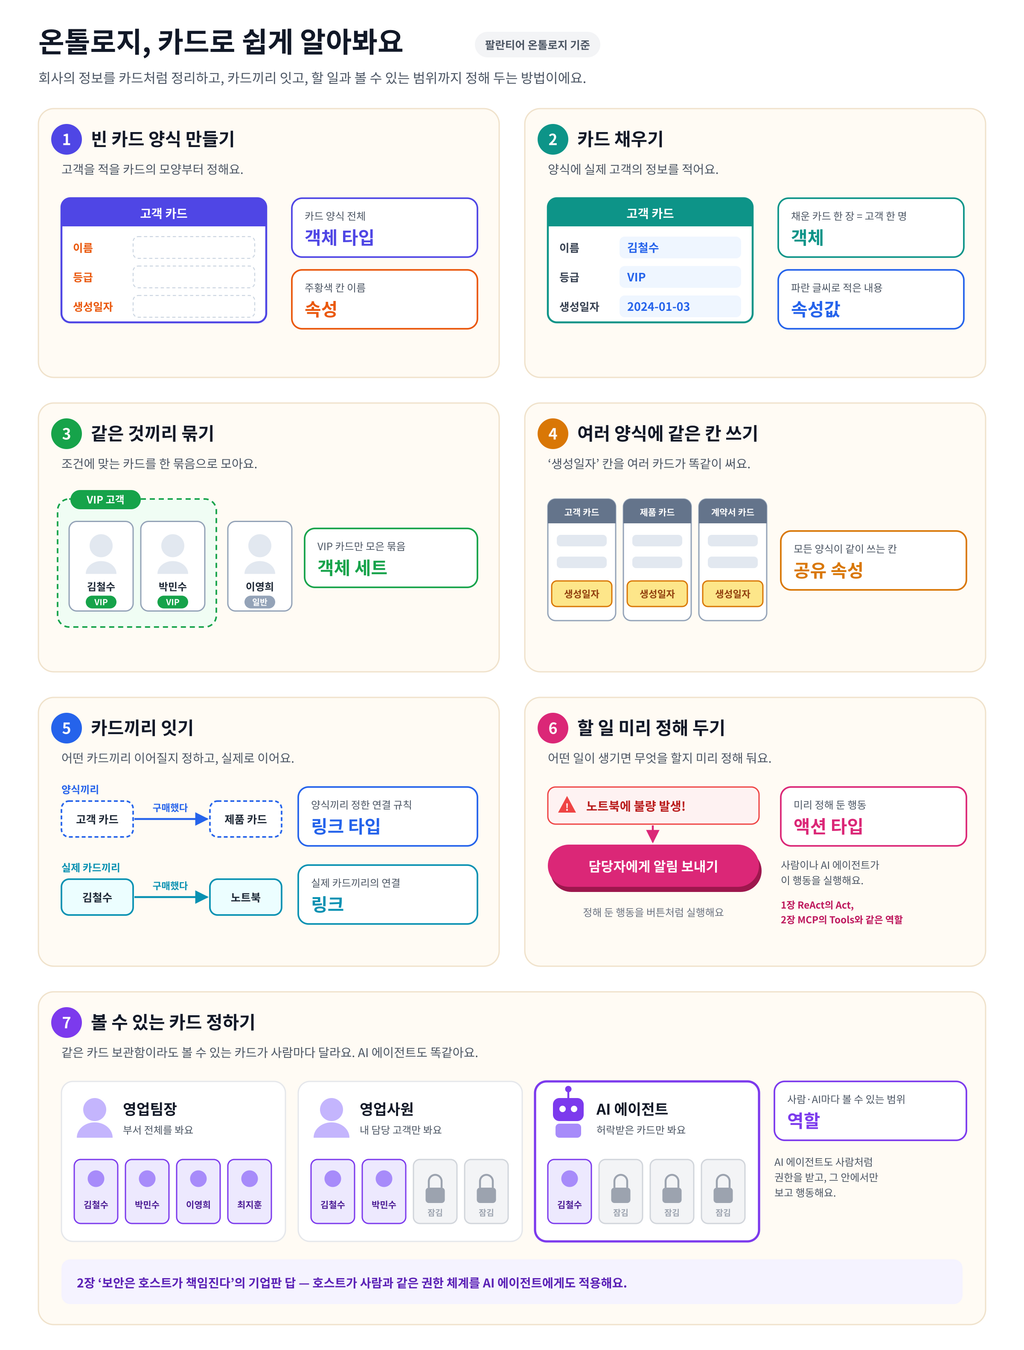

| 구성요소 | 의미 | 예시 |
|---|---|---|
| 객체 타입 | 테이블의 스키마와 같음 | "고객이란 이름, 등급, 생성일자를 가진 것"이라는 틀 |
| 객체 / 객체 세트 | 테이블의 한 행 / 여러 객체의 모음 | 고객A / VIP 고객 전체 |
| 속성 / 속성값 | 테이블의 열(객체가 가진 특징) / 특정 객체의 실제 값 | 이름, 날짜 / 김철수, VIP |
| 공유 속성 | 여러 객체 타입에서 공통으로 쓰는 속성 | "생성일자"를 고객·제품·계약서에서 일관되게 관리 |
| 링크 타입 / 링크 | 관계의 스키마 / 실제 관계의 인스턴스 | "구매했다" / "고객A가 제품B를 구매했다" |
| 액션 타입 | 데이터를 읽는 것을 넘어, 실제 변경과 행동까지 온톨로지 위에서 정의 | "불량 발생 시 담당자에게 알림 발송" |
| 역할 (Roles) | 직급, 부서, 지역에 따라 객체 단위까지 접근 권한 제어 | 영업팀장은 전체, 영업사원은 담당 고객만 |

- 액션 타입은 일반 DB와의 가장 큰 차이점
- AI 에이전트도 사람처럼 권한을 부여받아 그 범위 안의 데이터만 조회·실행 가능

| 관계형 DB (테이블) | 그래프 DB | 팔란티어 온톨로지 |
|---|---|---|
| 테이블 스키마 | - | 객체 타입 |
| 행 (Row) | 노드 | 객체 |
| 열 (Column) | - | 속성 |
| 필드 값 | - | 속성값 |
| 조인 (Join) | 엣지 | 링크 타입 |
| - | - | 액션 타입 (온톨로지만의 차별점) |

## 5. XAI

### 5-1. 블랙박스가 왜 문제인가
- AI 모델은 사람보다 정확하게 암을 발견하고 대출 심사·채용 판정을 하지만, "왜 그 결정을 내렸나요?"에는 답하지 못함
- 딥러닝 모델은 수백만~수십억 개의 파라미터가 복잡하게 얽혀 있어 사람이 직접 읽을 수 없음 
- AI가 권한을 받아 직접 알림을 보내고 데이터를 바꾸는 만큼, 판단이 곧 실행으로 이어짐

| 이유 | 내용 |
|---|---|
| 규제 (의료) | FDA는 진단 AI에 결론뿐 아니라 근거를 요구 |
| 규제 (금융) | EU AI Act는 대출·보험·채용 AI가 불리한 결정을 내렸을 때 고객에게 이유를 설명할 법적 의무를 부과 |
| 규제 (자율주행) | 사고 발생 시 왜 그 판단을 했는지 재현·설명이 가능해야 책임 소재를 따질 수 있음 |
| 디버깅 | 모델이 잘못 학습했을 때 어디가 문제인지 찾으려면 내부를 봐야 함 |

### 5-2. 기존 해결 시도들

| 방법 | 방식 | 한계 |
|---|---|---|
| ① 회귀 분석 (완전한 화이트박스) | 결과 = a×나이 + b×소득 + … 처럼 계수를 직접 읽을 수 있음 ("나이가 1 늘면 대출 거절 확률이 2% 오른다") | 이미지, 텍스트 등 복잡한 패턴에서는 충분한 정확도를 낼 수 없음 → 설명은 완벽한데 성능이 너무 낮음 |
| ② SHAP / LIME (사후적 설명) | 모델은 그대로 두고, 외부에서 "어떤 입력 특성이 결과에 얼마나 기여했는지"를 근사 계산 (예: 연체 이력 +34%, 소득 수준 −18%) | 입력을 바꿔 보며 역으로 추정하므로 "진짜 이유"가 아니라 "그렇게 보이는 것"일 수 있음 |
| ③ LLM + RAG (블랙박스로 블랙박스 설명) | 모델의 입력과 출력을 GPT에게 넘기고 "왜 이런 결정을 내렸을까요?"라고 물음 | GPT 자체도 블랙박스 → 그럴듯한 설명이 실제 내부 연산과 일치한다는 보장이 없음 |

| 방법 | 설명 가능성 | 성능 | 신뢰도 |
|---|---|---|---|
| 회귀 분석 | 완전한 화이트박스 | 낮음 | 높음 |
| SHAP / LIME | 근사 설명 | 모델 성능 유지 | 부분적 |
| LLM + RAG | 생성된 설명 | 모델 성능 유지 | 낮음 |

### 5-3. Mechanistic Interpretability (기계적 해석 가능성)

**1) 개념**
- "블랙박스 자체를 열어버리면 어떨까?"라는 질문에서 출발
- 모델이 무엇을 출력하는가가 아니라, 모델이 어떻게 그 답에 도달하는가를 이해하는 것
- 딥러닝 모델의 내부(가중치, 뉴런, 어텐션 헤드)를 직접 분석해서, 특정 기능이 모델 안 어디에 어떻게 구현되어 있는지 회로(circuit) 수준까지 역공학(reverse engineering)하는 연구 분야

| 구분 | 일반 XAI (SHAP, LIME 등) | Mechanistic Interpretability |
|---|---|---|
| 접근 방식 | 외부에서 관찰 | 내부를 직접 해부 |
| 핵심 질문 | "이 입력이 결과에 중요했나?" | "이 뉴런이 어떤 연산을 수행하나?" |
| 분석 수준 | 입력-출력 관계 | 가중치·회로 수준 |
| 성격 | 사후적 (post-hoc) | 구조적 (mechanistic) |

**2) 핵심 기법: Activation Patching (활성값 패칭)**
- "모델 내부의 어느 위치가 답을 결정하는지"를 찾는 실험 방법
   - ① 입력 두 개를 준비: A "프랑스의 수도는" → 파리 / B "독일의 수도는" → 베를린
   - ② B를 처리하는 도중, 특정 위치의 값을 A를 처리할 때 나온 활성값으로 바꿔 끼움
   - ③ 출력이 "베를린" → "파리"로 바뀌면 그 위치가 "어느 나라에 대한 질문인지"를 답까지 전달하는 핵심 경로, 바뀌지 않으면 그 위치 하나만으로는 답을 결정하지 않음

### 5-4. 핵심 개념 3가지

| 개념 | 질문 | 내용 |
|---|---|---|
| ① Features (특징) | 모델 안에는 무엇이 있는가? | 모델이 입력에서 알아챈 개념 (특정 단어, 언어·말투·상황 같은 추상적인 것), 입력에 그 개념이 등장하면 해당 뉴런(또는 뉴런 조합)의 활성값이 커짐 |
| ② Circuits (회로) | 그것들이 어떻게 연결되어 일하는가? | 여러 뉴런·어텐션 헤드가 연결되어 특정 기능을 수행하는 서브네트워크 (예: 간접 목적어 인식 회로 = 주어 탐지 헤드 + 동사 탐지 헤드 + 정보 조합 헤드) → 발견하면 기능 제거·이식 같은 조작이 이론적으로 가능 |
| ③ Superposition (중첩) | 그런데 왜 해석하기 어렵나? | 표현해야 할 개념은 수백만~수십억인데 뉴런 수는 훨씬 적음 → 하나의 뉴런이 여러 개념을 중첩해서 저장 |

- Feature의 저장 위치: 개별 뉴런(개념 하나가 뉴런 하나에 담김)보다, 방향 벡터(개념 하나가 여러 뉴런의 조합에 담김)인 경우가 많음
- Superposition이 생기는 이유
   - 모델은 특징을 뉴런 하나가 아니라 활성 공간 안의 방향으로 표현
   - 표현할 특징이 차원보다 많으면 방향을 조금씩 겹치게 배치 → 한 특징을 읽을 때 다른 특징이 조금 섞여 들어오는 간섭(interference) 발생
   - 특징이 드물게(sparse) 나타나 동시에 켜지는 일이 거의 없으므로, 간섭을 감수해도 더 많은 특징을 담는 이득이 큼
   - 특징 방향들이 뉴런 축과 맞지 않아 뉴런 하나를 보면 여러 특징이 조금씩 겹쳐 보임 → "뉴런 하나 = 개념 하나"가 아니라서 해석이 어려움
- 해결 도구: Sparse Autoencoder(SAE), 중첩된 개념들을 수학적으로 분리해서 각 개념을 독립적으로 추출하는 방법

> XAI는 "AI 설명을 어떻게 만들까"에서 "AI 내부를 어떻게 이해할까"로 진화하고 있으며, Mechanistic Interpretability는 그 최전선이자 AI가 커질수록 더 중요해지는 분야